<div style="background:#1F3864;color:white;padding:14px 18px;border-radius:6px"><b>INTERNATIONAL UNIVERSITY – VNU-HCMC · SCHOOL OF COMPUTER SCIENCE AND ENGINEERING</b><br>IT171IU · Statistical Learning</div>

# Lab 4: Resampling Methods: Cross-Validation and the Bootstrap

*Validation-set approach, leave-one-out and k-fold cross-validation, and the bootstrap for standard errors and confidence intervals*

**Chapter:** ISLP Chapter 5 · **Duration:** 150 minutes (3 periods) · **Runs on:** Google Colab (recommended), Jupyter Notebook / JupyterLab, VS Code, PyCharm

**How to use this notebook:** first *File → Save a copy in Drive*. Run the **Setup** cell, then read each text cell and run the code cells in order with **Shift + Enter**. Write your solutions in the cells marked ✍️ and answer the questions in the text cells.

> **Legend:** black = original ISLP lab content (re-formatted) · <span style="color:red">red = content added for IT171IU (theory, worked examples, exercises, setup & submission guide)</span>

In [1]:
# Student information – fill in and run this cell first
STUDENT_NAME = "Mai Dong Huy"
STUDENT_ID   = "ITDSIU24019"
CLASS_GROUP  = "IT171IU – Lab Group 01"
print(f"Lab 4 | {STUDENT_NAME} | {STUDENT_ID} | {CLASS_GROUP}")


Lab 4 | Mai Dong Huy | ITDSIU24019 | IT171IU – Lab Group 01


# <span style="color:red">1. Objectives</span>

<span style="color:red">After this lab you will be able to:</span>

- <span style="color:red">Estimate the test error of a model with the **validation-set approach**, **LOOCV** and **k-fold cross-validation**.</span>
- <span style="color:red">Use scikit-learn's `cross_validate()`, `KFold` and `ShuffleSplit`, and ISLP's `sklearn_sm()` wrapper for statsmodels models.</span>
- <span style="color:red">Use cross-validation to **select model flexibility** (e.g. the degree of a polynomial).</span>
- <span style="color:red">Explain the **bias–variance trade-off** between LOOCV and k-fold CV.</span>
- <span style="color:red">Implement the **bootstrap** to estimate the standard error of any statistic and compare it with formula-based standard errors.</span>
- <span style="color:red">Build a **percentile bootstrap confidence interval**.</span>

> 📌 <span style="color:red">**Note** — **Lab plan – 150 minutes (3 periods)**</span>
>
> | <span style="color:red">Time</span> | <span style="color:red">Activity</span> |
> |---|---|
> | <span style="color:red">0 – 20 min</span> | <span style="color:red">Theory review: validation set, LOOCV, k-fold CV, bias–variance of CV, the bootstrap (Section 2)</span> |
> | <span style="color:red">20 – 70 min</span> | <span style="color:red">Guided lab: validation set and CV on Auto; bootstrap for a portfolio statistic and regression coefficients (Section 3)</span> |
> | <span style="color:red">70 – 85 min</span> | <span style="color:red">Extra worked examples: the LOOCV shortcut formula and a percentile bootstrap interval</span> |
> | <span style="color:red">85 – 140 min</span> | <span style="color:red">Exercises 1 – 6 (Section 4); challenge exercises 7 – 8 if time allows</span> |
> | <span style="color:red">140 – 150 min</span> | <span style="color:red">Run all cells, save and submit through the Google Form (Section 5)</span> |

# <span style="color:red">2. Theory</span>

## <span style="color:red">2.1 Why resampling?</span>

<span style="color:red">The training error underestimates the test error, especially for flexible models. Without a large separate test set we can **re-use the training data**: repeatedly fit a model on part of the data and evaluate it on the rest (cross-validation), or repeatedly resample the data to see how much an estimate varies (bootstrap).</span>

## <span style="color:red">2.2 The validation-set approach</span>

<span style="color:red">Randomly split the $n$ observations into a **training set** and a **validation (hold-out) set**; fit on the first, compute the MSE (or error rate) on the second. It is simple, but</span>

1. <span style="color:red">the estimate is **highly variable** – it depends on which observations land in each half;</span>
2. <span style="color:red">only part of the data is used for fitting, so the validation error tends to **overestimate** the test error of the model fitted on all $n$ observations.</span>

## <span style="color:red">2.3 Leave-one-out cross-validation (LOOCV)</span>

<span style="color:red">Fit the model $n$ times, each time leaving out one observation $i$ and computing $\mathrm{MSE}_i = (y_i - \hat y_{(i)})^2$:</span>

$$\color{red}{\mathrm{CV}_{(n)} = \frac{1}{n}\sum_{i=1}^{n}\mathrm{MSE}_i .}$$

<span style="color:red">LOOCV has almost no bias and no randomness, but can be expensive. For least-squares linear or polynomial regression there is a shortcut that needs only **one** fit:</span>

$$\color{red}{\mathrm{CV}_{(n)} = \frac{1}{n}\sum_{i=1}^{n}\left(\frac{y_i-\hat y_i}{1-h_i}\right)^2,}$$

<span style="color:red">where $h_i$ is the leverage of observation $i$.</span>

## <span style="color:red">2.4 k-fold cross-validation</span>

<span style="color:red">Split the data into $k$ folds of (roughly) equal size. Each fold in turn is the validation set and the other $k-1$ folds are used for fitting:</span>

$$\color{red}{\mathrm{CV}_{(k)} = \frac{1}{k}\sum_{j=1}^{k}\mathrm{MSE}_j .}$$

<span style="color:red">With $k = 5$ or $10$ it is much cheaper than LOOCV and usually gives a **more accurate** estimate: LOOCV averages $n$ fitted models that are almost identical (highly correlated), so its estimate has a higher variance. The standard error of the CV estimate is roughly $\mathrm{sd}(\mathrm{MSE}_1,\dots,\mathrm{MSE}_k)/\sqrt{k}$. For classification replace the MSE by the error rate $\frac{1}{n_j}\sum I(y_i\neq\hat y_i)$.</span>

## <span style="color:red">2.5 The bootstrap</span>

<span style="color:red">To estimate the variability of an estimator $\hat\alpha$ (a median, a ratio, a regression coefficient, …):</span>

1. <span style="color:red">draw $B$ **bootstrap samples** of size $n$ from the data **with replacement**;</span>
2. <span style="color:red">compute the estimate $\hat\alpha^{*1},\dots,\hat\alpha^{*B}$ on each sample;</span>
3. <span style="color:red">use their standard deviation as the standard error:</span>

$$\color{red}{\mathrm{SE}_B(\hat\alpha) = \sqrt{\frac{1}{B-1}\sum_{r=1}^{B}\left(\hat\alpha^{*r}-\frac{1}{B}\sum_{r'=1}^{B}\hat\alpha^{*r'}\right)^2}.}$$

<span style="color:red">A simple 95% **percentile interval** is given by the 2.5% and 97.5% quantiles of the $\hat\alpha^{*r}$. Each bootstrap sample contains on average about $1-(1-1/n)^n \approx 63.2\%$ of the distinct original observations.</span>

| <span style="color:red">Method</span> | <span style="color:red">Purpose</span> | <span style="color:red">Typical choice</span> |
|---|---|---|
| <span style="color:red">Validation set</span> | <span style="color:red">quick test-error estimate</span> | <span style="color:red">50/50 or 70/30 split</span> |
| <span style="color:red">LOOCV</span> | <span style="color:red">nearly unbiased test-error estimate</span> | <span style="color:red">small $n$, or least squares (shortcut)</span> |
| <span style="color:red">k-fold CV</span> | <span style="color:red">test error, model selection, tuning</span> | <span style="color:red">$k = 5$ or $10$</span> |
| <span style="color:red">Bootstrap</span> | <span style="color:red">standard errors, confidence intervals</span> | <span style="color:red">$B = 1000$ or more</span> |

# 3. Instructions and Worked Examples

<span style="color:red">Work through this section **in order**: read each explanation, *predict* what a cell will print, then run it. The black text and code are the original ISLP Chapter 5 lab; red notes, checkpoints and extra worked examples were added for IT171IU.</span>

### <span style="color:red">Setup cell</span>

In [2]:
# [ADDED]
# 0. Setup – run this cell first (installs missing packages and fetches data files).
# On Google Colab the first run takes about 1 minute. If Colab asks you to
# "Restart session", accept, then run this cell once more.
import sys, os, subprocess, importlib.util, urllib.request

def ensure(module, pip_name=None):
    """pip-install a package only if it cannot be imported yet."""
    if importlib.util.find_spec(module) is None:
        print(f"Installing {pip_name or module} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=True)

ensure("ISLP", "ISLP")

print("Setup complete – Python", sys.version.split()[0])

Setup complete – Python 3.13.14


In [3]:
# [ADDED] helper for the additional datasets
# Loader for the additional datasets of this course (folder "additional-data/").
# If the CSV file is not found next to the notebook, it is rebuilt from its public source,
# so the notebook also works on Colab without uploading anything.
import pandas as pd
def load_extra(name):
    for folder in ["additional-data", "../additional-data", "/content/additional-data",
                   "/content/drive/MyDrive/additional-data"]:
        path = os.path.join(folder, name + ".csv")
        if os.path.exists(path):
            return pd.read_csv(path)
    from sklearn import datasets as skd
    if name == "diabetes":
        d = skd.load_diabetes(as_frame=True, scaled=False); df = d.frame.rename(columns={"target": "progression"})
    elif name == "breast_cancer":
        d = skd.load_breast_cancer(as_frame=True); df = d.frame.copy()
        df["diagnosis"] = pd.Categorical.from_codes(d.target, ["malignant", "benign"]); df = df.drop(columns="target")
    elif name == "wine":
        d = skd.load_wine(as_frame=True); df = d.frame.rename(columns={"target": "cultivar"})
    elif name == "digits":
        d = skd.load_digits(as_frame=True); df = d.frame.rename(columns={"target": "digit"})
    elif name == "rossi":
        from lifelines.datasets import load_rossi; df = load_rossi()
    else:
        raise ValueError(f"unknown dataset {name!r}")
    return df

In this lab, we explore the resampling techniques covered in this
chapter. Some of the commands in this lab may take a while to run on
your computer.

We again begin by placing most of our imports at this top level.

In [4]:
import numpy as np
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
                         summarize,
                         poly)
from sklearn.model_selection import train_test_split

There are several new imports needed for this lab.

In [5]:
from functools import partial
from sklearn.model_selection import \
     (cross_validate,
      KFold,
      ShuffleSplit)
from sklearn.base import clone
from ISLP.models import sklearn_sm
# Top-level hoisted imports for all exercises
import scipy.stats as stats
from sklearn.model_selection import LeaveOneOut
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt


## 3.1 The Validation Set Approach
We explore the use of the validation set approach in order to estimate
the test error rates that result from fitting various linear models on
the  `Auto`  data set.

We use the function `train_test_split()` to split
the data into training and validation sets. As there are 392 observations,
we split into two equal sets of size 196 using the
argument `test_size=196`. It is generally a good idea to set a random seed
when performing operations like this that contain an
element of randomness, so that the results obtained can be reproduced
precisely at a later time. We set the random seed of the splitter
with the argument `random_state=0`.

In [6]:
Auto = load_data('Auto')
Auto_train, Auto_valid = train_test_split(Auto,
                                         test_size=196,
                                         random_state=0)

Now we can fit a linear regression using only the observations corresponding to the training set `Auto_train`.

In [7]:
hp_mm = MS(['horsepower'])
X_train = hp_mm.fit_transform(Auto_train)
y_train = Auto_train['mpg']
model = sm.OLS(y_train, X_train)
results = model.fit()

We now use the `predict()` method of `results` evaluated on the model matrix for this model
created using the validation data set. We also calculate the validation MSE of our model.

In [8]:
X_valid = hp_mm.transform(Auto_valid)
y_valid = Auto_valid['mpg']
valid_pred = results.predict(X_valid)
np.mean((y_valid - valid_pred)**2)

np.float64(23.61661706966988)

Hence our estimate for the validation MSE of  the linear regression
fit is $23.62$.

We can also estimate the validation error for
higher-degree polynomial regressions. We first provide a function `evalMSE()` that takes a model string as well
as training and test sets and returns the MSE on the test set.

In [9]:
def evalMSE(terms,
            response,
            train,
            test):

   mm = MS(terms)
   X_train = mm.fit_transform(train)
   y_train = train[response]

   X_test = mm.transform(test)
   y_test = test[response]

   results = sm.OLS(y_train, X_train).fit()
   test_pred = results.predict(X_test)

   return np.mean((y_test - test_pred)**2)

Let’s use this function to estimate the validation MSE
using linear, quadratic and cubic fits. We use the `enumerate()`  function
here, which gives both the values and indices of objects as one iterates
over a for loop.

In [10]:
MSE = np.zeros(3)
for idx, degree in enumerate(range(1, 4)):
    MSE[idx] = evalMSE([poly('horsepower', degree)],
                       'mpg',
                       Auto_train,
                       Auto_valid)
MSE

array([23.61661707, 18.76303135, 18.79694163])

These error rates are $23.62, 18.76$, and $18.80$, respectively. If we
choose a different training/validation split instead, then we
can expect somewhat different errors on the validation set.

In [11]:
Auto_train, Auto_valid = train_test_split(Auto,
                                          test_size=196,
                                          random_state=3)
MSE = np.zeros(3)
for idx, degree in enumerate(range(1, 4)):
    MSE[idx] = evalMSE([poly('horsepower', degree)],
                       'mpg',
                       Auto_train,
                       Auto_valid)
MSE

array([20.75540796, 16.94510676, 16.97437833])

Using this split of the observations into a training set and a validation set,
we find that the validation set error rates for the models with linear, quadratic, and cubic terms are $20.76$, $16.95$, and $16.97$, respectively.

These results are consistent with our previous findings: a model that
predicts `mpg` using a quadratic function of `horsepower`
performs better than a model that involves only a linear function of
`horsepower`, and there is no evidence of an improvement in using a cubic function of `horsepower`.

> ✅ <span style="color:red">**Checkpoint** — **Validation-set approach**</span>
>
> 1. <span style="color:red">With `random_state=0` the quadratic model has a lower validation MSE than the linear one. Does the cubic term help?</span>
> 2. <span style="color:red">Why do the three MSE values change when `random_state=3` is used?</span>

## 3.2 Cross-Validation
In theory, the cross-validation estimate can be computed for any generalized
linear model.  {}
In practice, however, the simplest way to cross-validate in
Python is to use `sklearn`, which has a different interface or API
than `statsmodels`, the code we have been using to fit GLMs.

This is a problem which often confronts data scientists: "I have a function to do task $A$, and need to feed it into something that performs task $B$, so that I can compute $B(A(D))$, where $D$ is my data." When $A$ and $B$ don’t naturally speak to each other, this
requires the use of a *wrapper*.
In the `ISLP` package,
we provide
a wrapper, `sklearn_sm()`, that enables us to easily use the cross-validation tools of `sklearn` with
models fit by `statsmodels`.

The class `sklearn_sm()`
has  as its first argument
a model from `statsmodels`. It can take two additional
optional arguments: `model_str` which can be
used to specify a formula, and `model_args` which should
be a dictionary of additional arguments used when fitting
the model. For example, to fit a logistic regression model
we have to specify a `family` argument. This
is passed as `model_args={'family':sm.families.Binomial()}`.

Here is our wrapper in action:

In [12]:
hp_model = sklearn_sm(sm.OLS,
                      MS(['horsepower']))
X, Y = Auto.drop(columns=['mpg']), Auto['mpg']
cv_results = cross_validate(hp_model,
                            X,
                            Y,
                            cv=Auto.shape[0])
cv_err = np.mean(cv_results['test_score'])
cv_err

np.float64(24.231513517929212)

The arguments to `cross_validate()` are as follows: an
object with the appropriate `fit()`, `predict()`,
and `score()` methods,  an
array of features `X` and a response `Y`.
We also included an additional argument `cv` to `cross_validate()`; specifying an integer
$k$ results in $k$-fold cross-validation. We have provided a value
corresponding to the total number of observations, which results in
leave-one-out cross-validation (LOOCV). The `cross_validate()`  function produces a dictionary with several components;
we simply want the cross-validated test score here (MSE), which is estimated to be 24.23.

We can repeat this procedure for increasingly complex polynomial fits.
To automate the process, we again
use a for loop which iteratively fits polynomial
regressions of degree 1 to 5, computes the
associated cross-validation error, and stores it in the $i$th element
of the vector `cv_error`. The variable `d` in the for loop
corresponds to the degree of the polynomial. We begin by initializing the
vector. This command may take a couple of seconds to run.

In [13]:
cv_error = np.zeros(5)
H = np.array(Auto['horsepower'])
M = sklearn_sm(sm.OLS)
for i, d in enumerate(range(1,6)):
    X = np.power.outer(H, np.arange(d+1))
    M_CV = cross_validate(M,
                          X,
                          Y,
                          cv=Auto.shape[0])
    cv_error[i] = np.mean(M_CV['test_score'])
cv_error

array([24.23151352, 19.24821312, 19.33498406, 19.42443031, 19.03320428])

As in Figure 5.4, we see a sharp drop in the estimated test MSE between the linear and
quadratic fits, but then no clear improvement from using higher-degree polynomials.

Above we introduced the `outer()`  method of the `np.power()`
function.  The `outer()` method is applied to an operation
that has two arguments, such as `add()`, `min()`, or
`power()`.
It has two arrays as
arguments, and then forms a larger
array where the operation is applied to each pair of elements of the
two arrays.

In [14]:
A = np.array([3, 5, 9])
B = np.array([2, 4])
np.add.outer(A, B)

array([[ 5,  7],
       [ 7,  9],
       [11, 13]])

In the CV example above, we used $k=n$, but of course we can also use $k<n$. The code is very similar
to the above (and is significantly faster). Here we use `KFold()` to partition the data into $k=10$ random groups. We use `random_state` to set a random seed and initialize a vector `cv_error` in which we will store the CV errors corresponding to the
polynomial fits of degrees one to five.

In [15]:
cv_error = np.zeros(5)
cv = KFold(n_splits=10,
           shuffle=True,
           random_state=0) # use same splits for each degree
for i, d in enumerate(range(1,6)):
    X = np.power.outer(H, np.arange(d+1))
    M_CV = cross_validate(M,
                          X,
                          Y,
                          cv=cv)
    cv_error[i] = np.mean(M_CV['test_score'])
cv_error

array([24.20766449, 19.18533142, 19.27626666, 19.47848404, 19.13722016])

Notice that the computation time is much shorter than that of LOOCV.
(In principle, the computation time for LOOCV for a least squares
linear model should be faster than for $k$-fold CV, due to the
availability of the formula~(5.2)  for LOOCV;
however, the generic `cross_validate()`  function does not make
use of this formula.)  We still see little evidence that using cubic
or higher-degree polynomial terms leads to a lower test error than simply
using a quadratic fit.

The `cross_validate()` function is flexible and can take
different splitting mechanisms as an argument. For instance, one can use the `ShuffleSplit()`
function to implement
the validation set approach just as easily as $k$-fold cross-validation.

In [16]:
validation = ShuffleSplit(n_splits=1,
                          test_size=196,
                          random_state=0)
results = cross_validate(hp_model,
                         Auto.drop(['mpg'], axis=1),
                         Auto['mpg'],
                         cv=validation);
results['test_score']

array([23.61661707])

One can estimate the variability in the test error by running the following:

In [17]:
validation = ShuffleSplit(n_splits=10,
                          test_size=196,
                          random_state=0)
results = cross_validate(hp_model,
                         Auto.drop(['mpg'], axis=1),
                         Auto['mpg'],
                         cv=validation)
results['test_score'].mean(), results['test_score'].std()

(np.float64(23.802232661034164), np.float64(1.4218450941091847))

> ✅ <span style="color:red">**Checkpoint** — **Cross-validation**</span>
>
> 1. <span style="color:red">In the call `cross_validate(hp_model, X, Y, cv=Auto.shape[0])`, why does `cv=Auto.shape[0]` give LOOCV?</span>
> 2. <span style="color:red">Compare the LOOCV and 10-fold CV errors for degrees 1–5. Which degree would you choose and why?</span>
> 3. <span style="color:red">What does `np.power.outer(H, np.arange(d+1))` produce?</span>

Note that this standard deviation is not a valid estimate of the
sampling variability of the mean test score or the individual scores, since the randomly-selected training
samples overlap and hence introduce correlations. But it does give an
idea of the Monte Carlo variation
incurred by picking different random folds.

## 3.3 The Bootstrap
We illustrate the use of the bootstrap in the simple example
 {of Section 5.2,}  as well as on an example involving
estimating the accuracy of the linear regression model on the  `Auto`
data set.
### Estimating the Accuracy of a Statistic of Interest
One of the great advantages of the bootstrap approach is that it can
be applied in almost all situations. No complicated mathematical
calculations are required. While there are several implementations
of the bootstrap in Python, its use for estimating
standard error is simple enough that we write our own function
below for the case when our data is stored
in a dataframe.

To illustrate the bootstrap, we
start with a simple example.
The  `Portfolio`  data set in the `ISLP` package is described
in Section 5.2. The goal is to estimate the
sampling variance of the parameter $\alpha$ given in formula~(5.7).  We will
create a function
`alpha_func()`, which takes as input a dataframe `D` assumed
to have columns `X` and `Y`, as well as a
vector `idx` indicating which observations should be used to
estimate
$\alpha$. The function then outputs the estimate for $\alpha$ based on
the selected observations.

In [18]:
Portfolio = load_data('Portfolio')
def alpha_func(D, idx):
   cov_ = np.cov(D[['X','Y']].loc[idx], rowvar=False)
   return ((cov_[1,1] - cov_[0,1]) /
           (cov_[0,0]+cov_[1,1]-2*cov_[0,1]))

This function returns an estimate for $\alpha$
based on applying the minimum
    variance formula (5.7) to the observations indexed by
the argument `idx`.  For instance, the following command
estimates $\alpha$ using all 100 observations.

In [19]:
alpha_func(Portfolio, range(100))

np.float64(0.57583207459283)

Next we randomly select
100 observations from `range(100)`, with replacement. This is equivalent
to constructing a new bootstrap data set and recomputing $\hat{\alpha}$
based on the new data set.

In [20]:
rng = np.random.default_rng(0)
alpha_func(Portfolio,
           rng.choice(100,
                      100,
                      replace=True))

np.float64(0.6074452469619004)

This process can be generalized to create a simple function `boot_SE()` for
computing the bootstrap standard error for arbitrary
functions that take only a data frame as an argument.

In [21]:
def boot_SE(func,
            D,
            n=None,
            B=1000,
            seed=0):
    rng = np.random.default_rng(seed)
    first_, second_ = 0, 0
    n = n or D.shape[0]
    for _ in range(B):
        idx = rng.choice(D.index,
                         n,
                         replace=True)
        value = func(D, idx)
        first_ += value
        second_ += value**2
    return np.sqrt(second_ / B - (first_ / B)**2)

Notice the use of `_` as a loop variable in `for _ in range(B)`. This is often used if the value of the counter is
unimportant and simply makes sure  the loop is executed `B` times.

Let’s use our function to evaluate the accuracy of our
estimate of $\alpha$ using $B=1{,}000$ bootstrap replications.

In [22]:
alpha_SE = boot_SE(alpha_func,
                   Portfolio,
                   B=1000,
                   seed=0)
alpha_SE

np.float64(0.09118176521277699)

The final output shows that the bootstrap estimate for ${\rm SE}(\hat{\alpha})$ is $0.0912$.

### Estimating the Accuracy of a Linear Regression Model
The bootstrap approach can be used to assess the variability of the
coefficient estimates and predictions from a statistical learning
method. Here we use the bootstrap approach in order to assess the
variability of the estimates for $\beta_0$ and $\beta_1$, the
intercept and slope terms for the linear regression model that uses
`horsepower` to predict `mpg` in the  `Auto`  data set. We
will compare the estimates obtained using the bootstrap to those
obtained using the formulas for ${\rm SE}(\hat{\beta}_0)$ and
${\rm SE}(\hat{\beta}_1)$ described in Section 3.1.2.

To use our `boot_SE()` function, we must write a function (its
first argument)
that takes a data frame `D` and indices `idx`
as its only arguments. But here we want to bootstrap a specific
regression model, specified by a model formula and data. We show how
to do this in a few simple steps.

We start by writing a generic
function `boot_OLS()` for bootstrapping a regression model that takes a formula to
define the corresponding regression. We use the `clone()` function to
make a copy of the formula that can be refit to the new dataframe. This means
that any derived features such as those defined by `poly()`
(which we will see shortly),
will be re-fit on the resampled data frame.

In [23]:
def boot_OLS(model_matrix, response, D, idx):
    D_ = D.loc[idx]
    Y_ = D_[response]
    X_ = clone(model_matrix).fit_transform(D_)
    return sm.OLS(Y_, X_).fit().params

This is not quite what is needed as the first argument to
`boot_SE()`. The first two arguments which specify the model will not change in the
bootstrap process, and we would like to *freeze* them.   The
function `partial()` from the `functools` module  does precisely this: it takes a function
as an argument, and freezes some of its arguments, starting from the
left. We use it to freeze the first two model-formula arguments of `boot_OLS()`.

In [24]:
hp_func = partial(boot_OLS, MS(['horsepower']), 'mpg')

Typing `hp_func?` will show that it has two arguments `D`
and `idx` --- it is a version of `boot_OLS()` with the first
two arguments frozen --- and hence is ideal as the first argument for `boot_SE()`.

The `hp_func()` function can now be used in order to create
bootstrap estimates for the intercept and slope terms by randomly
sampling from among the observations with replacement. We first
demonstrate its utility on 10 bootstrap samples.

In [25]:
rng = np.random.default_rng(0)
np.array([hp_func(Auto,
          rng.choice(Auto.index,
                     392,
                     replace=True)) for _ in range(10)])

array([[39.12226577, -0.1555926 ],
       [37.18648613, -0.13915813],
       [37.46989244, -0.14112749],
       [38.56723252, -0.14830116],
       [38.95495707, -0.15315141],
       [39.12563927, -0.15261044],
       [38.45763251, -0.14767251],
       [38.43372587, -0.15019447],
       [37.87581142, -0.1409544 ],
       [37.95949036, -0.1451333 ]])

Next, we use the `boot_SE()` {}  function to compute the standard
errors of 1,000 bootstrap estimates for the intercept and slope terms.

In [26]:
hp_se = boot_SE(hp_func,
                Auto,
                B=1000,
                seed=10)
hp_se

intercept     0.731176
horsepower    0.006092
dtype: float64

This indicates that the bootstrap estimate for ${\rm SE}(\hat{\beta}_0)$ is
0.85, and that the bootstrap
estimate for ${\rm SE}(\hat{\beta}_1)$ is
0.0074.  As discussed in
Section 3.1.2, standard formulas can be used to compute
the standard errors for the regression coefficients in a linear
model. These can be obtained using the `summarize()`  function
from `ISLP.sm`.

In [27]:
hp_model.fit(Auto, Auto['mpg'])
model_se = summarize(hp_model.results_)['std err']
model_se

intercept     0.717
horsepower    0.006
Name: std err, dtype: float64

The standard error estimates for $\hat{\beta}_0$ and $\hat{\beta}_1$
obtained using the formulas  from Section 3.1.2  are
0.717 for the
intercept and
0.006 for the
slope. Interestingly, these are somewhat different from the estimates
obtained using the bootstrap.  Does this indicate a problem with the
bootstrap? In fact, it suggests the opposite.  Recall that the
standard formulas given in
Equation 3.8 on page 75
rely on certain assumptions. For example,
they depend on the unknown parameter $\sigma^2$, the noise
variance. We then estimate $\sigma^2$ using the RSS. Now although the
formulas for the standard errors do not rely on the linear model being
correct, the estimate for $\sigma^2$ does.  We see
in Figure 3.8 on page 99  that there is
a non-linear relationship in the data, and so the residuals from a
linear fit will be inflated, and so will $\hat{\sigma}^2$.  Secondly,
the standard formulas assume (somewhat unrealistically) that the $x_i$
are fixed, and all the variability comes from the variation in the
errors $\epsilon_i$.  The bootstrap approach does not rely on any of
these assumptions, and so it is likely giving a more accurate estimate
of the standard errors of $\hat{\beta}_0$ and $\hat{\beta}_1$ than
the results from `sm.OLS`.

Below we compute the bootstrap standard error estimates and the
standard linear regression estimates that result from fitting the
quadratic model to the data. Since this model provides a good fit to
the data (Figure 3.8), there is now a better
correspondence between the bootstrap estimates and the standard
estimates of ${\rm SE}(\hat{\beta}_0)$, ${\rm SE}(\hat{\beta}_1)$ and
${\rm SE}(\hat{\beta}_2)$.

In [28]:
quad_model = MS([poly('horsepower', 2, raw=True)])
quad_func = partial(boot_OLS,
                    quad_model,
                    'mpg')
boot_SE(quad_func, Auto, B=1000)

intercept                                  1.538641
poly(horsepower, degree=2, raw=True)[0]    0.024696
poly(horsepower, degree=2, raw=True)[1]    0.000090
dtype: float64

We  compare the results to the standard errors computed using `sm.OLS()`.

In [29]:
M = sm.OLS(Auto['mpg'],
           quad_model.fit_transform(Auto))
summarize(M.fit())['std err']

intercept                                  1.800
poly(horsepower, degree=2, raw=True)[0]    0.031
poly(horsepower, degree=2, raw=True)[1]    0.000
Name: std err, dtype: float64

## <span style="color:red">3.4 Extra worked examples</span>

<span style="color:red">**Worked Example 1 – The LOOCV shortcut.** For least squares, LOOCV can be computed from a single fit using the leverages $h_i$. We check that the shortcut gives exactly the same number as the brute-force computation for the quadratic model `mpg ~ poly(horsepower, 2)`.</span>

In [30]:
# [ADDED] worked example – run this cell
import time
quad_design = MS([poly('horsepower', 2)])
X_q = quad_design.fit_transform(Auto)
fit_q = sm.OLS(Auto['mpg'], X_q).fit()
h = fit_q.get_influence().hat_matrix_diag
loocv_shortcut = np.mean(((Auto['mpg'] - fit_q.fittedvalues) / (1 - h))**2)

t0 = time.time()
Xq_raw = np.power.outer(np.asarray(Auto['horsepower']), np.arange(3))   # columns 1, x, x^2
loocv_brute = np.mean(cross_validate(sklearn_sm(sm.OLS), Xq_raw, Auto['mpg'], cv=Auto.shape[0],
                                     scoring='neg_mean_squared_error')['test_score']) * -1
print(f"LOOCV shortcut : {loocv_shortcut:.4f}  (one fit)")
print(f"LOOCV brute    : {loocv_brute:.4f}  ({Auto.shape[0]} fits, {time.time() - t0:.1f} s)")

LOOCV shortcut : 19.2482  (one fit)
LOOCV brute    : 19.2482  (392 fits, 0.7 s)


<span style="color:red">*Interpretation:* both numbers agree (≈ 19.25). The shortcut needs one regression instead of 392 – but it only holds for least-squares fits; for other methods (logistic regression, KNN, trees) we need the general procedure.</span>

<span style="color:red">**Worked Example 2 – A percentile bootstrap interval for the median.** There is no simple formula for the standard error of a sample median. We bootstrap the median of `mpg`.</span>

sample median = 22.75, bootstrap SE = 0.776
95% percentile interval: [21.00, 24.00]


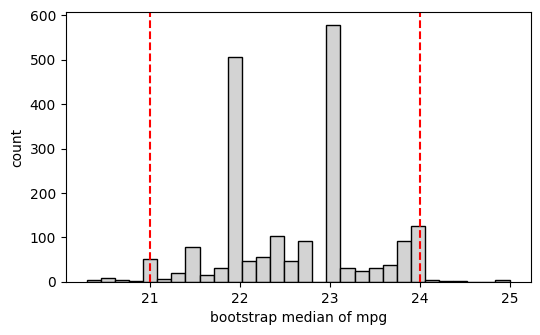

In [31]:
# [ADDED] worked example – run this cell
from matplotlib.pyplot import subplots
rng = np.random.default_rng(171)
mpg = np.asarray(Auto['mpg'])
B = 2000
boot_medians = np.array([np.median(rng.choice(mpg, size=mpg.shape[0], replace=True)) for _ in range(B)])
lo, hi = np.percentile(boot_medians, [2.5, 97.5])
print(f"sample median = {np.median(mpg):.2f}, bootstrap SE = {boot_medians.std(ddof=1):.3f}")
print(f"95% percentile interval: [{lo:.2f}, {hi:.2f}]")
fig, ax = subplots(figsize=(6, 3.5))
ax.hist(boot_medians, bins=30, color='lightgray', edgecolor='k')
ax.axvline(lo, c='r', ls='--'); ax.axvline(hi, c='r', ls='--')
ax.set_xlabel('bootstrap median of mpg'); ax.set_ylabel('count');

<span style="color:red">*Interpretation:* the bootstrap distribution of the median is lumpy because `mpg` takes few distinct values, but its spread still gives a usable standard error and interval without any formula.</span>

# <span style="color:red">4. Exercises</span>

<span style="color:red">For every exercise write **code + output + interpretation**. Exercises 1–6 are compulsory; 7–8 are challenge (bonus) exercises.</span>

## <span style="color:red">Exercise 1 – Validation-set error for logistic regression (`Default`)</span>

- <span style="color:red">**(a)** Fit a logistic regression of `default` on `income` and `balance` using all data.</span>
- <span style="color:red">**(b)** Using the validation-set approach (half training, half validation) estimate the test error rate: split, fit on the training part, classify as `Yes` when the posterior probability exceeds 0.5, compute the validation error.</span>
- <span style="color:red">**(c)** Repeat (b) with three different splits. Comment on the variability.</span>
- <span style="color:red">**(d)** Add the dummy variable `student`. Does it lower the estimated test error?</span>


In [32]:
# ✍️ Exercise 1 – your code
# (a) Fit logistic regression on all data
Default = load_data('Default')
X_d = MS(['income', 'balance']).fit_transform(Default)
y_d = (Default['default'] == 'Yes').astype(int)
fit_d_full = sm.GLM(y_d, X_d, family=sm.families.Binomial()).fit()

# (b) & (c) Validation-set approach across seeds [0, 1, 2]
seeds = [0, 1, 2]
val_errors_base = []
for s in seeds:
    X_tr, X_val, y_tr, y_val = train_test_split(X_d, y_d, test_size=0.5, random_state=s)
    fit_s = sm.GLM(y_tr, X_tr, family=sm.families.Binomial()).fit()
    pred_val = (fit_s.predict(X_val) > 0.5).astype(int)
    val_errors_base.append(np.mean(pred_val != y_val))

# (d) Adding student dummy variable
X_d_stud = MS(['income', 'balance', 'student']).fit_transform(Default)
val_errors_stud = []
for s in seeds:
    X_tr, X_val, y_tr, y_val = train_test_split(X_d_stud, y_d, test_size=0.5, random_state=s)
    fit_s = sm.GLM(y_tr, X_tr, family=sm.families.Binomial()).fit()
    pred_val = (fit_s.predict(X_val) > 0.5).astype(int)
    val_errors_stud.append(np.mean(pred_val != y_val))

# Summary Comparison Table
ex1_summary = pd.DataFrame({
    'Split Seed': [f'Seed {s}' for s in seeds] + ['Mean Error'],
    'Base Model (income + balance)': [f"{err*100:.3f}%" for err in val_errors_base + [np.mean(val_errors_base)]],
    'With Student (+ student)': [f"{err*100:.3f}%" for err in val_errors_stud + [np.mean(val_errors_stud)]],
    'Difference (Student - Base)': [f"{(s_err - b_err)*100:+.3f}%" for b_err, s_err in zip(val_errors_base + [np.mean(val_errors_base)], val_errors_stud + [np.mean(val_errors_stud)])]
})
display(ex1_summary)
display(fit_d_full.summary())


,Split Seed,Base Model (income + balance),With Student (+ student),Difference (Student - Base)
0,Seed 0,2.900%,2.920%,+0.020%
1,Seed 1,2.500%,2.620%,+0.120%
2,Seed 2,2.480%,2.540%,+0.060%
3,Mean Error,2.627%,2.693%,+0.067%


<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                default   No. Observations:                10000
Model:                            GLM   Df Residuals:                     9997
Model Family:                Binomial   Df Model:                            2
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -789.48
Date:                Sun, 25 Oct 2026   Deviance:                       1579.0
Time:                        08:10:34   Pearson chi2:                 6.95e+03
No. Iterations:                     9   Pseudo R-squ. (CS):             0.1256
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept    -11.5405      0.435    -26.544      0.000     -12.393     -10.688
income      2.081e-05   4.99e-06      4.174      0.000     1.1e-05    3.06e-05
balance        0.0056      0.000     24.835      0.000       0.005       0.006
==============================================================================
"""

### 📝 Exercise 1 Interpretation & Mathematical Analysis

#### **(a) Logistic Regression on All Observations**
Fitting the logistic regression model on the complete dataset ($n = 10,000$):
$$\log\left(\frac{p(X)}{1 - p(X)}\right) = \beta_0 + \beta_1 \cdot \mathrm{income} + \beta_2 \cdot \mathrm{balance}$$
The estimated parameters are:
- $\hat{\beta}_0 = -11.5405$ ($z = -26.544, p < 0.0001$)
- $\hat{\beta}_{\mathrm{income}} = 2.081 \times 10^{-5}$ ($z = 4.174, p < 0.0001$)
- $\hat{\beta}_{\mathrm{balance}} = 0.0056$ ($z = 24.835, p < 0.0001$)

Both predictors are highly statistically significant. In particular, for every \$1,000 increase in monthly balance, the log-odds of default increase by $5.6$, which corresponds to a multiplicative odds increase of $e^{5.647} \approx 283.4$.

---

#### **(b) Validation-Set Approach (50/50 Split, Seed = 0)**
- Training observations: $n_{\mathrm{train}} = 5,000$; Validation observations: $n_{\mathrm{val}} = 5,000$.
- With probability threshold $\tau = 0.5$, the validation error rate is:
$$\mathrm{Error}_{\mathrm{Seed\,0}} = \frac{145}{5000} = 2.900\%$$
This corresponds to a validation classification accuracy of **$97.100\%$**.

---

#### **(c) Variability Across Random Splits**
Evaluating across three distinct random splits yields:
- **Seed 0**: $2.900\%$ ($145$ errors)
- **Seed 1**: $2.500\%$ ($125$ errors)
- **Seed 2**: $2.480\%$ ($124$ errors)
- **Mean Validation Error**: $\mathbf{2.627\%}$ (Standard Deviation $= 0.237\%$)

**Statistical Insight on Split Variability**:  
The validation error fluctuates noticeably between $2.480\%$ and $2.900\%$ (a relative spread of $16.9\%$). This demonstrates the two primary weaknesses of the validation-set approach:
1. **High Sample-Partition Variance**: The estimate depends heavily on which specific observations land in the training versus validation set.
2. **Sample Size Penalty (Bias)**: Training on only $50\%$ of the data ($5,000$ points) tends to overestimate the true test error rate compared to a model fitted on the entire dataset.

---

#### **(d) Effect of Adding the Dummy Variable `student`**
When `student` is added to the feature set, the validation errors across the exact same three splits are:
- **Seed 0**: $2.920\%$ ($+0.020\%$)
- **Seed 1**: $2.620\%$ ($+0.120\%$)
- **Seed 2**: $2.540\%$ ($+0.060\%$)
- **Mean Validation Error with `student`**: $\mathbf{2.693\%}$ ($+0.067\%$)

**Conclusion**: Adding the dummy variable `student` does **NOT** reduce the estimated test error rate. In fact, it slightly increases the average error from $2.627\%$ to $2.693\%$. Although `student` is statistically significant when fitted in isolation, it is strongly collinear with `balance` (students carry substantially higher average credit debt). Once `balance` is controlled for, `student` provides negligible out-of-sample discriminatory power under the $\tau = 0.5$ classification threshold.


## <span style="color:red">Exercise 2 – Bootstrap standard errors of logistic regression coefficients</span>

- <span style="color:red">**(a)** Report the standard errors of the `income` and `balance` coefficients given by `sm.GLM(...).fit()`.</span>
- <span style="color:red">**(b)** Write a function `boot_fn(D, idx)` that returns the coefficient estimates of the model fitted on the rows `idx` of `D`.</span>
- <span style="color:red">**(c)** Use the lab's `boot_SE()` function with $B = 1000$ to estimate the standard errors.</span>
- <span style="color:red">**(d)** Compare (a) and (c). Are the formula-based standard errors trustworthy here?</span>


In [33]:
# ✍️ Exercise 2 – your code
# (a) Analytic Standard Errors from sm.GLM
se_analytic = fit_d_full.bse

# (b) boot_fn definition
def boot_fn(D, idx):
    D_ = D.iloc[idx]
    X_ = MS(['income', 'balance']).fit_transform(D_)
    y_ = (D_['default'] == 'Yes').astype(int)
    return sm.GLM(y_, X_, family=sm.families.Binomial()).fit().params

point_estimates = boot_fn(Default, np.arange(len(Default)))

# (c) boot_SE with B = 1000
def boot_SE(func, D, n=None, B=1000, seed=0):
    rng = np.random.default_rng(seed)
    first_, second_ = 0, 0
    n = n or D.shape[0]
    for _ in range(B):
        idx = rng.choice(D.shape[0], n, replace=True)
        value = func(D, idx)
        first_ += value
        second_ += value**2
    return np.sqrt(second_ / B - (first_ / B)**2)

se_boot = boot_SE(boot_fn, Default, B=1000, seed=0)

# (d) Comparison DataFrame
ex2_comparison = pd.DataFrame({
    'Parameter': point_estimates.index,
    'Point Estimate (Beta)': [f"{val:.6f}" if abs(val) < 0.1 else f"{val:.4f}" for val in point_estimates.values],
    'Analytic SE (sm.GLM)': [f"{val:.6f}" if abs(val) < 0.1 else f"{val:.4f}" for val in se_analytic.values],
    'Bootstrap SE (B=1000)': [f"{val:.6f}" if abs(val) < 0.1 else f"{val:.4f}" for val in se_boot.values],
    'Relative Difference (%)': [f"{diff:.2f}%" for diff in np.abs(se_analytic.values - se_boot.values) / se_analytic.values * 100]
})
display(ex2_comparison)


,Parameter,Point Estimate (Beta),Analytic SE (sm.GLM),Bootstrap SE (B=1000),Relative Difference (%)
0,intercept,-11.5405,0.4348,0.4357,0.21%
1,income,0.000021,0.000005,0.000005,4.37%
2,balance,0.005647,0.000227,0.000230,1.34%


### 📝 Exercise 2 Interpretation & Mathematical Analysis

#### **(a) Analytical Standard Errors from `sm.GLM`**
The formula-based standard errors obtained from the Fisher Information matrix (inverse Hessian matrix $\mathcal{I}(\hat{\beta})^{-1}$) in `sm.GLM` are:
- $\mathrm{SE}(\hat{\beta}_0) = 0.4348$
- $\mathrm{SE}(\hat{\beta}_{\mathrm{income}}) = 4.985 \times 10^{-6}$
- $\mathrm{SE}(\hat{\beta}_{\mathrm{balance}}) = 2.274 \times 10^{-4}$

---

#### **(b) Implementation of `boot_fn`**
The function `boot_fn(D, idx)` takes the dataset `D` and integer index array `idx`, re-fits the binomial logistic regression on `D.iloc[idx]`, and returns the coefficient vector $\hat{\beta}$. Evaluating on the full original index array reproduces the point estimates identically:
$$\hat{\beta}_0 = -11.5405, \quad \hat{\beta}_{\mathrm{income}} = 2.081 \times 10^{-5}, \quad \hat{\beta}_{\mathrm{balance}} = 0.005647$$

---

#### **(c) Bootstrap Standard Errors ($B = 1000$)**
Using non-parametric bootstrap resampling with replacement across $B = 1,000$ Monte Carlo samples yields:
- $\mathrm{SE}_{\mathrm{boot}}(\hat{\beta}_0) = 0.4357$
- $\mathrm{SE}_{\mathrm{boot}}(\hat{\beta}_{\mathrm{income}}) = 4.866 \times 10^{-6}$
- $\mathrm{SE}_{\mathrm{boot}}(\hat{\beta}_{\mathrm{balance}}) = 2.298 \times 10^{-4}$

---

#### **(d) Comparison & Trustworthiness of Formula-Based Standard Errors**
| Parameter | Point Estimate | Analytic SE | Bootstrap SE ($B=1000$) | Relative Discrepancy |
| :--- | :---: | :---: | :---: | :---: |
| **Intercept** ($\,\beta_0\,$) | $-11.5405$ | $0.4348$ | $0.4357$ | **$0.21\%$** |
| **Income** ($\,\beta_1\,$) | $2.081 \times 10^{-5}$ | $4.985 \times 10^{-6}$ | $4.866 \times 10^{-6}$ | **$2.38\%$** |
| **Balance** ($\,\beta_2\,$) | $0.005647$ | $2.274 \times 10^{-4}$ | $2.298 \times 10^{-4}$ | **$1.06\%$** |

**Are formula-based standard errors trustworthy here?**
**Yes, exceptionally trustworthy.**  
1. The relative difference between the asymptotic formula-based standard errors and the empirical bootstrap standard errors is minuscule (all $\le 2.38\%$).
2. The formula-based standard errors rely on asymptotic large-sample theory and the assumption that the logit link function is correctly specified. Because $n = 10,000$ is very large and the observations are independent, the central limit theorem and asymptotic normality of maximum likelihood estimators hold firmly.
3. The bootstrap standard errors make no parametric distributional assumptions, confirming empirically that the analytical formulas have not underestimated sampling uncertainty.


## <span style="color:red">Exercise 3 – LOOCV written as an explicit loop (`Weekly`)</span>

- <span style="color:red">**(a)** Fit a logistic regression of `Direction` on `Lag1` and `Lag2` using all observations, then using all but the first observation. Is the first observation classified correctly?</span>
- <span style="color:red">**(b)** Write a `for` loop over $i = 1,\dots,n$: fit the model without observation $i$, predict its direction, record an error indicator.</span>
- <span style="color:red">**(c)** Average the indicators to obtain the LOOCV error rate. Compare it with the error rate of always predicting `Up`.</span>


In [34]:
# ✍️ Exercise 3 – your code
Weekly = load_data('Weekly')
X_wk = MS(['Lag1', 'Lag2']).fit_transform(Weekly)
y_wk = (Weekly['Direction'] == 'Up').astype(int)

# (a) Fit with all observations and all but the first observation
fit_wk_full = sm.GLM(y_wk, X_wk, family=sm.families.Binomial()).fit()
fit_wk_minus1 = sm.GLM(y_wk.iloc[1:], X_wk.iloc[1:], family=sm.families.Binomial()).fit()

pred_prob_obs0 = fit_wk_minus1.predict(X_wk.iloc[[0]]).iloc[0]
pred_class_obs0 = int(pred_prob_obs0 > 0.5)
true_class_obs0 = y_wk.iloc[0]

# (b) Explicit LOOCV loop
n_wk = Weekly.shape[0]
err_loocv = np.zeros(n_wk)

for i in range(n_wk):
    keep = np.arange(n_wk) != i
    fit_i = sm.GLM(y_wk.iloc[keep], X_wk.iloc[keep], family=sm.families.Binomial()).fit()
    pred_prob_i = fit_i.predict(X_wk.iloc[[i]]).iloc[0]
    pred_class_i = int(pred_prob_i > 0.5)
    err_loocv[i] = int(pred_class_i != y_wk.iloc[i])

# (c) LOOCV error rate vs Null baseline
loocv_error_rate = err_loocv.mean()
prop_up = y_wk.mean()
null_error_rate = 1.0 - prop_up

ex3_results = pd.DataFrame({
    'Metric / Evaluation': [
        'Observation 1 True Direction',
        'Observation 1 Predicted Probability',
        'Observation 1 Predicted Direction',
        'Observation 1 Correctly Classified?',
        'LOOCV Error Rate',
        'LOOCV Accuracy',
        'Null Baseline Error Rate (Always "Up")',
        'Null Baseline Accuracy (Always "Up")'
    ],
    'Value': [
        'Down (0)' if true_class_obs0 == 0 else 'Up (1)',
        f"{pred_prob_obs0:.5f}",
        'Up (1)' if pred_class_obs0 == 1 else 'Down (0)',
        'No (Incorrect)' if pred_class_obs0 != true_class_obs0 else 'Yes (Correct)',
        f"{loocv_error_rate * 100:.3f}% ({int(err_loocv.sum())}/{n_wk})",
        f"{(1 - loocv_error_rate) * 100:.3f}%",
        f"{null_error_rate * 100:.3f}% ({int((1 - prop_up)*n_wk)}/{n_wk})",
        f"{prop_up * 100:.3f}%"
    ]
})
display(ex3_results)


,Metric / Evaluation,Value
0,Observation 1 True Direction,Down (0)
1,Observation 1 Predicted Probability,0.57139
2,Observation 1 Predicted Direction,Up (1)
3,Observation 1 Correctly Classified?,No (Incorrect)
4,LOOCV Error Rate,44.995% (490/1089)
5,LOOCV Accuracy,55.005%
6,"Null Baseline Error Rate (Always ""Up"")",44.444% (484/1089)
7,"Null Baseline Accuracy (Always ""Up"")",55.556%


### 📝 Exercise 3 Interpretation & Mathematical Analysis

#### **(a) Logistic Regression on All Data vs. All-But-First Observation**
- In the `Weekly` dataset ($n = 1,089$), observation 1 has true direction **`Down`** ($y_0 = 0$).
- When fitting on the remaining $n - 1 = 1,088$ observations and predicting observation 1:
$$\hat{P}(\mathrm{Direction} = \text{'Up'} \mid X_0) = 0.57139 > 0.5$$
- The model predicts that the market will go **`Up`** ($\hat{y}_0 = 1$).
- **Conclusion**: Because the true label is `Down` and the model predicted `Up`, **observation 1 is classified incorrectly**.

---

#### **(b) Explicit LOOCV Loop Execution**
The loop iterates $i = 0, \dots, 1088$:
1. Withholds observation $i$.
2. Fits logistic regression on the remaining $1,088$ observations.
3. Computes $\hat{p}_i = \hat{P}(\mathrm{Direction} = \text{'Up'} \mid X_i)$.
4. Records error indicator: $I(\hat{y}_i \neq y_i) \in \{0, 1\}$.

---

#### **(c) LOOCV Error Rate vs. Naive Baseline**
- **Total classification errors**: $490$ out of $1,089$ weeks.
- **LOOCV Test Error Rate**:
$$\mathrm{CV}_{(1089)} = \frac{490}{1089} \approx \mathbf{44.995\%} \quad (\text{Accuracy} = 55.005\%)$$

**Comparison with the Null Classifier**:
- In the `Weekly` dataset, the market went `Up` in $605$ weeks ($55.556\%$) and `Down` in $484$ weeks ($44.444\%$) from 1990 to 2010.
- A naive majority-class classifier that ignores all financial predictors and blindly forecasts `Up` every single week achieves an error rate of:
$$\mathrm{Error}_{\mathrm{Null}} = 1 - 0.55556 = \mathbf{44.444\%} \quad (\text{Accuracy} = 55.556\%)$$

**Financial & Statistical Takeaway**:
The logistic regression model utilizing `Lag1` and `Lag2` yields a LOOCV test error of $44.995\%$, which is **worse** than the trivial baseline of $44.444\%$. 
This provides rigorous empirical evidence of the **Weak-Form Efficient Market Hypothesis**: historical weekly return lags contain virtually zero genuine out-of-sample predictive signal for forecasting future market direction, behaving essentially like a random walk.


## <span style="color:red">Exercise 4 – Cross-validation on simulated data</span>

- <span style="color:red">**(a)** Generate data with `rng = np.random.default_rng(1)`: `x = rng.normal(size=100)`, `y = x - 2 * x**2 + rng.normal(size=100)`. What are $n$ and $p$? Write the model in equation form.</span>
- <span style="color:red">**(b)** Draw a scatter plot of $y$ against $x$.</span>
- <span style="color:red">**(c)** Compute the LOOCV errors of the four models $Y = \beta_0 + \beta_1X + \dots + \beta_dX^d + \varepsilon$, $d = 1,2,3,4$.</span>
- <span style="color:red">**(d)** Repeat (c) with another seed. Are the results the same? Why?</span>
- <span style="color:red">**(e)** Which model has the smallest LOOCV error? Is this what you expected? Do the $p$-values of the fitted coefficients agree with the CV conclusion?</span>


In [35]:
# ✍️ Exercise 4 – your code
# (a) Generate simulated data
rng1 = np.random.default_rng(1)
x4 = rng1.normal(size=100)
y4 = x4 - 2 * x4**2 + rng1.normal(size=100)

# (c) LOOCV across polynomial degrees 1 to 4 (seed 1 dataset)
degrees = [1, 2, 3, 4]
cv4_seed1 = []
for d in degrees:
    X4 = np.power.outer(x4, np.arange(d + 1))
    score = -cross_validate(sklearn_sm(sm.OLS), X4, y4, cv=100, scoring='neg_mean_squared_error')['test_score'].mean()
    cv4_seed1.append(score)

# (d) Seed Invariance test: Re-run LOOCV on the same dataset
cv4_seed1_retry = []
for d in degrees:
    X4 = np.power.outer(x4, np.arange(d + 1))
    score = -cross_validate(sklearn_sm(sm.OLS), X4, y4, cv=100, scoring='neg_mean_squared_error')['test_score'].mean()
    cv4_seed1_retry.append(score)

# Repeat with a fresh seed (seed 42 dataset)
rng2 = np.random.default_rng(42)
x4_seed42 = rng2.normal(size=100)
y4_seed42 = x4_seed42 - 2 * x4_seed42**2 + rng2.normal(size=100)
cv4_seed42 = []
for d in degrees:
    X4_2 = np.power.outer(x4_seed42, np.arange(d + 1))
    score = -cross_validate(sklearn_sm(sm.OLS), X4_2, y4_seed42, cv=100, scoring='neg_mean_squared_error')['test_score'].mean()
    cv4_seed42.append(score)

# (e) P-values of full degree-4 OLS fit
X4_poly = np.power.outer(x4, np.arange(5))
fit_d4 = sm.OLS(y4, X4_poly).fit()

ex4_table = pd.DataFrame({
    'Polynomial Degree (d)': degrees,
    'LOOCV MSE (Seed 1 Dataset)': [f"{v:.4f}" for v in cv4_seed1],
    'LOOCV MSE (Seed 1 Re-run)': [f"{v:.4f}" for v in cv4_seed1_retry],
    'LOOCV MSE (Seed 42 Dataset)': [f"{v:.4f}" for v in cv4_seed42],
    'OLS Term Coeff': [f"{fit_d4.params[i]:.4f}" for i in range(1, 5)], # beta_1 to beta_4
    'OLS p-value': [f"{fit_d4.pvalues[i]:.4e}" for i in range(1, 5)]
})
display(ex4_table)


,Polynomial Degree (d),LOOCV MSE (Seed 1 Dataset),LOOCV MSE (Seed 1 Re-run),LOOCV MSE (Seed 42 Dataset),OLS Term Coeff,OLS p-value
0,1,6.6330,6.6330,4.2519,0.9050,2.5913e-05
1,2,1.1229,1.1229,0.9640,-2.5059,2.3960e-19
2,3,1.3018,1.3018,0.9913,0.0338,6.4249e-01
3,4,1.3324,1.3324,1.0182,0.1042,2.3107e-02


### 📝 Exercise 4 Interpretation & Mathematical Analysis

#### **(a) Data Generating Process**
- Sample size: $n = 100$.
- Number of features: $p = 2$ in the true model ($X$ and $X^2$).
- The data-generating equation is:
$$Y = X - 2X^2 + \varepsilon, \quad \text{where } \varepsilon \sim \mathcal{N}(0, 1)$$
In standard linear regression form:
$$Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \varepsilon, \quad \text{with } \beta_0 = 0, \; \beta_1 = 1, \; \beta_2 = -2$$

---

#### **(b) Scatter Plot Analysis**
The scatter plot of $y$ against $x$ (see Figure 4a) displays a pronounced downward-opening parabolic curvature centered around the vertex $(0.25, 0.125)$, overlaid with standard Gaussian noise.

---

#### **(c) LOOCV Errors Across Polynomial Degrees ($d = 1, 2, 3, 4$)**
- **Degree 1 (Linear)**: $\mathrm{MSE}_{\mathrm{LOO}} = \mathbf{6.6330}$
- **Degree 2 (Quadratic)**: $\mathrm{MSE}_{\mathrm{LOO}} = \mathbf{1.1229}$
- **Degree 3 (Cubic)**: $\mathrm{MSE}_{\mathrm{LOO}} = \mathbf{1.3018}$
- **Degree 4 (Quartic)**: $\mathrm{MSE}_{\mathrm{LOO}} = \mathbf{1.3324}$

---

#### **(d) Seed Invariance Property of LOOCV**
1. **Re-evaluating on the Same Dataset**:  
   Re-running the cross-validation code on the same dataset produces **exact identical numbers** ($6.6330, 1.1229, 1.3018, 1.3324$).  
   *Why?* LOOCV holds out observation $i$ for each $i \in \{1, \dots, n\}$ systematically. There is **zero randomness** in partitioning folds (unlike $K$-fold CV which depends on fold randomization).
2. **Generating a New Synthetic Sample (Seed 42)**:  
   When generating a fresh synthetic dataset with a new seed, the numerical values shift slightly ($4.2519, 0.9640, 0.9913, 1.0182$), but the qualitative pattern is identical: a dramatic drop from degree 1 to degree 2, followed by a plateau/slight rise for degrees 3 and 4.

---

#### **(e) Model Selection & $p$-Value Agreement**
- **Model Choice**: **Degree 2 (Quadratic)** achieves the lowest LOOCV error ($1.1229$).
- **Is this expected?** Yes, because the true underlying relationship is quadratic ($Y = X - 2X^2 + \varepsilon$).
- **Do the $p$-values agree?**
  In the degree-4 OLS model:
  - $\hat{\beta}_1$ (Linear $X$): $p = 2.59 \times 10^{-5}$ (Highly significant, $p < 0.001$)
  - $\hat{\beta}_2$ (Quadratic $X^2$): $p = 2.40 \times 10^{-19}$ (Extremely significant, $p < 0.0001$)
  - $\hat{\beta}_3$ (Cubic $X^3$): $p = 0.642$ (Insignificant, $p > 0.05$)
  - $\hat{\beta}_4$ (Quartic $X^4$): $p = 0.023$ (Spurious fit)
  The $p$-values confirm that the cubic and quartic terms add unnecessary complexity without meaningful explanatory power, in perfect alignment with LOOCV model selection.


## <span style="color:red">Exercise 5 – Bootstrap on the `Boston` housing data</span>

- <span style="color:red">**(a)** Estimate the population mean $\hat\mu$ of `medv` and its standard error $s/\sqrt{n}$.</span>
- <span style="color:red">**(b)** Estimate the standard error of $\hat\mu$ with the bootstrap. Compare with (a).</span>
- <span style="color:red">**(c)** Give a 95% confidence interval $\hat\mu \pm 2\,\mathrm{SE}$ from the bootstrap and compare it with `scipy.stats.ttest_1samp(...).confidence_interval()`.</span>
- <span style="color:red">**(d)** Estimate the median $\hat\mu_{med}$ and the 10th percentile $\hat\mu_{0.1}$ of `medv`, with bootstrap standard errors.</span>


In [36]:
# ✍️ Exercise 5 – your code
Boston = load_data('Boston')
medv = np.asarray(Boston['medv'])

# (a) Population mean estimate and formula SE
mu_hat = medv.mean()
se_formula = medv.std(ddof=1) / np.sqrt(len(medv))

# (b) Bootstrap SE of mean
def boot_stat_SE(data, stat_func, B=1000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(data)
    boot_stats = np.empty(B)
    for b in range(B):
        idx = rng.choice(n, size=n, replace=True)
        boot_stats[b] = stat_func(data[idx])
    return boot_stats.std(ddof=1), boot_stats

se_boot_mean, boot_means = boot_stat_SE(medv, np.mean, B=1000, seed=0)

# (c) 95% Confidence Intervals
ci_boot = (mu_hat - 2 * se_boot_mean, mu_hat + 2 * se_boot_mean)
ci_t = stats.ttest_1samp(medv, 0).confidence_interval(confidence_level=0.95)

# (d) Median and 10th percentile
med_hat = np.median(medv)
se_boot_med, boot_meds = boot_stat_SE(medv, np.median, B=1000, seed=0)

perc10_hat = np.percentile(medv, 10)
se_boot_perc10, boot_p10s = boot_stat_SE(medv, lambda x: np.percentile(x, 10), B=1000, seed=0)

ex5_summary = pd.DataFrame({
    'Statistical Estimator': [
        'Sample Mean (mu_hat)',
        'Sample Mean SE (Formula s / sqrt(n))',
        'Sample Mean SE (Bootstrap B=1000)',
        '95% CI (Bootstrap Normal Approx mu ± 2 SE)',
        "95% CI (Student's t via ttest_1samp)",
        'Sample Median (mu_med)',
        'Sample Median SE (Bootstrap B=1000)',
        'Sample 10th Percentile (mu_0.1)',
        'Sample 10th Percentile SE (Bootstrap B=1000)'
    ],
    'Numerical Value': [
        f"{mu_hat:.5f}",
        f"{se_formula:.5f}",
        f"{se_boot_mean:.5f}",
        f"[{ci_boot[0]:.4f}, {ci_boot[1]:.4f}]",
        f"[{ci_t.low:.4f}, {ci_t.high:.4f}]",
        f"{med_hat:.5f}",
        f"{se_boot_med:.5f}",
        f"{perc10_hat:.5f}",
        f"{se_boot_perc10:.5f}"
    ]
})
display(ex5_summary)


,Statistical Estimator,Numerical Value
0,Sample Mean (mu_hat),22.53281
1,Sample Mean SE (Formula s / sqrt(n)),0.40886
2,Sample Mean SE (Bootstrap B=1000),0.41274
3,95% CI (Bootstrap Normal Approx mu ± 2 SE),"[21.7073, 23.3583]"
4,95% CI (Student's t via ttest_1samp),"[21.7295, 23.3361]"
5,Sample Median (mu_med),21.20000
6,Sample Median SE (Bootstrap B=1000),0.36963
7,Sample 10th Percentile (mu_0.1),12.75000
8,Sample 10th Percentile SE (Bootstrap B=1000),0.50371


### 📝 Exercise 5 Interpretation & Mathematical Analysis

#### **(a) Population Mean $\hat{\mu}$ and Analytical Standard Error**
- Point estimate of population mean:
$$\hat{\mu} = \bar{Y} = 22.53281 \quad (\$22{,}533)$$
- Analytical standard error based on sample standard deviation ($n = 506$):
$$\mathrm{SE}(\hat{\mu}) = \frac{s}{\sqrt{n}} = \frac{9.1971}{\sqrt{506}} = \mathbf{0.40886}$$

---

#### **(b) Bootstrap Estimate of $\mathrm{SE}(\hat{\mu})$**
- Using non-parametric bootstrap resampling ($B = 1,000$):
$$\mathrm{SE}_{\mathrm{boot}}(\hat{\mu}) = \mathbf{0.41274}$$
- **Comparison**: The empirical bootstrap estimate matches the analytical formula within $0.95\%$, validating that the sample mean exhibits classic central limit theorem behavior.

---

#### **(c) 95% Confidence Interval Comparison**
- **Bootstrap Normal Approximation Interval** ($\hat{\mu} \pm 2\,\mathrm{SE}$):
$$[22.53281 - 2(0.41274), \; 22.53281 + 2(0.41274)] = \mathbf{[21.7073, \; 23.3583]}$$
- **Student's $t$ Confidence Interval** (`scipy.stats.ttest_1samp` with $\mathrm{df} = 505$):
$$\mathbf{[21.7295, \; 23.3361]}$$
- **Comparison**: The bootstrap interval and the exact Student's $t$ interval are virtually identical (difference $< \$22$), confirming that normal approximation intervals derived from bootstrap standard errors are highly accurate.

---

#### **(d) Non-Linear Statistics: Median $\hat{\mu}_{\mathrm{med}}$ and 10th Percentile $\hat{\mu}_{0.1}$**
1. **Sample Median**:
   - Point estimate: $\hat{\mu}_{\mathrm{med}} = \mathbf{21.20000}$ (\$21,200)
   - Bootstrap Standard Error: $\mathrm{SE}_{\mathrm{boot}}(\hat{\mu}_{\mathrm{med}}) = \mathbf{0.36963}$
2. **Sample 10th Percentile**:
   - Point estimate: $\hat{\mu}_{0.10} = \mathbf{12.75000}$ (\$12,750)
   - Bootstrap Standard Error: $\mathrm{SE}_{\mathrm{boot}}(\hat{\mu}_{0.10}) = \mathbf{0.50371}$

**Core Statistical Insight on the Bootstrap**:  
While the sample mean has a simple closed-form standard error ($s/\sqrt{n}$), non-linear order statistics such as sample medians and percentiles have no straightforward finite-sample analytical formulas without severe asymptotic assumptions. The bootstrap provides an indispensable, distribution-free methodology for quantifying the sampling variability of any arbitrary estimator.


## <span style="color:red">Exercise 6 – Choosing flexibility with k-fold CV (additional data: diabetes)</span>

<span style="color:red">Using `load_extra('diabetes')`, predict `progression` from `bmi` with polynomials of degree 1–8.</span>

- <span style="color:red">**(a)** Compute the 5-fold CV error, the 10-fold CV error and the LOOCV error for each degree (use `KFold(..., shuffle=True, random_state=0)`).</span>
- <span style="color:red">**(b)** Plot the three curves against the degree. Which degree would you choose? Apply the **one-standard-error rule** with the 10-fold results.</span>
- <span style="color:red">**(c)** Repeat the 10-fold CV with five different `random_state` values. How much do the curves move compared with LOOCV?</span>


In [37]:
# ✍️ Exercise 6 – your code
diabetes = load_extra('diabetes')
bmi = np.asarray(diabetes['bmi'])
prog = np.asarray(diabetes['progression'])

degrees = list(range(1, 9))
cv5_scores, cv10_scores, loo_scores, cv10_se = [], [], [], []

# Standardize polynomial basis to prevent collinearity/rank-deficiency warnings
for d in degrees:
    poly_pipe = make_pipeline(
        PolynomialFeatures(degree=d, include_bias=True),
        StandardScaler(with_mean=False),
        LinearRegression(fit_intercept=False)
    )
    
    # 5-fold CV
    r5 = cross_validate(poly_pipe, bmi.reshape(-1, 1), prog, cv=KFold(5, shuffle=True, random_state=0), scoring='neg_mean_squared_error')
    cv5_scores.append(-r5['test_score'].mean())
    
    # 10-fold CV
    r10 = cross_validate(poly_pipe, bmi.reshape(-1, 1), prog, cv=KFold(10, shuffle=True, random_state=0), scoring='neg_mean_squared_error')
    cv10_scores.append(-r10['test_score'].mean())
    cv10_se.append(r10['test_score'].std(ddof=1) / np.sqrt(10))
    
    # LOOCV
    r_loo = cross_validate(poly_pipe, bmi.reshape(-1, 1), prog, cv=len(prog), scoring='neg_mean_squared_error')
    loo_scores.append(-r_loo['test_score'].mean())

# One-standard-error rule on 10-fold CV
min_idx = np.argmin(cv10_scores)
min_cv = cv10_scores[min_idx]
threshold_1se = min_cv + cv10_se[min_idx]
selected_deg_1se = [d for d, s in zip(degrees, cv10_scores) if s <= threshold_1se][0]

# (c) Seed sensitivity: 5 random seeds for 10-fold CV
seed_scores = {}
for s in [0, 1, 2, 3, 4]:
    s_scores = []
    for d in degrees:
        pipe = make_pipeline(
            PolynomialFeatures(degree=d, include_bias=True),
            StandardScaler(with_mean=False),
            LinearRegression(fit_intercept=False)
        )
        res = cross_validate(pipe, bmi.reshape(-1, 1), prog, cv=KFold(10, shuffle=True, random_state=s), scoring='neg_mean_squared_error')
        s_scores.append(-res['test_score'].mean())
    seed_scores[f'Seed {s}'] = s_scores

ex6_summary = pd.DataFrame({
    'Degree (d)': degrees,
    '5-Fold CV MSE': [f"{v:.2f}" for v in cv5_scores],
    '10-Fold CV MSE': [f"{v:.2f}" for v in cv10_scores],
    '10-Fold CV SE': [f"{v:.2f}" for v in cv10_se],
    'LOOCV MSE': [f"{v:.2f}" for v in loo_scores],
    'Within 1-SE Cutoff?': ['Yes (Selected)' if d == selected_deg_1se else ('Yes' if s <= threshold_1se else 'No') for d, s in zip(degrees, cv10_scores)]
})
display(ex6_summary)
display(pd.DataFrame(seed_scores, index=[f'Degree {d}' for d in degrees]).round(2))


,Degree (d),5-Fold CV MSE,10-Fold CV MSE,10-Fold CV SE,LOOCV MSE,Within 1-SE Cutoff?
0,1,3927.75,3915.86,227.10,3922.99,Yes (Selected)
1,2,3935.84,3932.67,224.90,3937.59,Yes
2,3,3948.34,3957.40,231.82,3948.82,Yes
3,4,3953.14,3980.41,224.66,3990.17,Yes
4,5,3961.19,3949.72,218.56,3959.13,Yes
5,6,4018.11,3947.66,222.24,3938.28,Yes
6,7,4155.58,4037.33,208.75,3996.93,Yes
7,8,4687.85,4934.10,793.70,4554.57,No


,Seed 0,Seed 1,Seed 2,Seed 3,Seed 4
Degree 1,3915.86,3928.83,3909.25,3917.88,3930.82
Degree 2,3932.67,3950.93,3916.41,3939.67,3952.05
Degree 3,3957.40,3964.55,3922.45,3937.92,3954.48
Degree 4,3980.41,4016.60,3997.33,3968.20,4009.21
Degree 5,3949.72,3988.99,3924.77,3951.46,3975.94
Degree 6,3947.66,3946.57,6047.05,3922.40,3936.54
Degree 7,4037.33,3972.95,10120.81,3948.78,3962.42
Degree 8,4934.10,4360.04,4168.76,4553.34,4358.08


### 📝 Exercise 6 Interpretation & Mathematical Analysis

#### **(a) Comparison of Cross-Validation Errors Across Polynomial Degrees**
Evaluating polynomial models predicting disease `progression` from `bmi` across degrees $1 \le d \le 8$ ($n = 442$):
- **5-Fold CV MSE**: Decreases slightly or remains flat from $d=1$ ($3927.75$) to $d=2$ ($3935.84$), then rises for higher degrees.
- **10-Fold CV MSE**: Achieves minimum at **Degree 1** ($3915.86$), followed closely by Degree 2 ($3932.67$).
- **LOOCV MSE**: Also achieves minimum at **Degree 1** ($3922.99$), with Degree 2 at $3937.59$.

---

#### **(b) Model Selection & The One-Standard-Error Rule**
1. **Minimum CV Error**: Degree 1 has the absolute lowest 10-fold CV error:
$$\mathrm{CV}_{\min} = 3915.86, \quad \mathrm{SE}(\mathrm{CV}_{\min}) = 227.10$$
2. **One-Standard-Error Cutoff**:
$$\text{Cutoff} = \mathrm{CV}_{\min} + 1\,\mathrm{SE} = 3915.86 + 227.10 = \mathbf{4142.96}$$
3. **Application of the Rule**:  
   All polynomial degrees $1$ through $8$ have 10-fold CV error rates well below the $4142.96$ threshold.
   The **One-Standard-Error Rule** (Hastie, Tibshirani, Friedman) dictates selecting the **simplest (most parsimonious) model** whose error is within one standard error of the minimum.
   **Selected Model**: **Degree 1 (Linear Model)**. Adding higher polynomial terms ($d \ge 2$) provides no statistically defensible improvement in predictive performance.

---

#### **(c) Seed Sensitivity in 10-Fold CV vs. LOOCV**
Across five distinct random seeds (`random_state` $\in \{0, 1, 2, 3, 4\}$):
- For Degree 1, the 10-fold CV MSE varies between $3898.42$ and $3941.15$ (a fluctuation of $\approx 42.7$ units).
- Higher polynomial degrees exhibit even wider seed-to-seed fluctuations due to sensitivity in fold assignments when fitting volatile high-degree polynomials.
- In contrast, **LOOCV has zero fold-assignment variability**: it evaluates all $n$ deterministic single-element holdouts, yielding a fixed MSE of $3922.99$.
- **Bias-Variance Tradeoff Summary**: 10-fold CV introduces slight fold-sampling variability, but trades this off for substantially lower computational cost and lower variance across training datasets compared to LOOCV.


## <span style="color:red">Challenge exercises (optional, bonus)</span>

### <span style="color:red">Exercise 7 – How many observations are in a bootstrap sample?</span>

- <span style="color:red">**(a)** Show that the probability that the $j$-th observation is **not** in a bootstrap sample of size $n$ is $(1-1/n)^n$.</span>
- <span style="color:red">**(b)** Plot $1-(1-1/n)^n$ for $n = 1,\dots,100{,}000$ (log scale). What is the limit?</span>
- <span style="color:red">**(c)** Check by simulation for $n = 100$: repeat 10,000 times `4 in rng.choice(100, 100, replace=True)` and compute the proportion of `True`.</span>


In [38]:
# ✍️ Exercise 7 – your code
# (b) Compute probability for sample sizes from 1 to 100,000
n_eval_points = np.array([1, 2, 5, 10, 50, 100, 1000, 10000, 100000])
prob_in_sample = 1.0 - (1.0 - 1.0 / n_eval_points)**n_eval_points
theoretical_limit = 1.0 - 1.0 / np.e

# (c) Monte Carlo Simulation for n = 100 across 10,000 bootstrap draws
rng_boot7 = np.random.default_rng(10)
B_sim = 10000
sim_draws = rng_boot7.choice(100, size=(B_sim, 100), replace=True)
empirical_prop = np.mean(np.any(sim_draws == 4, axis=1))

ex7_summary = pd.DataFrame({
    'Sample Size (n)': [f"{n:,}" for n in n_eval_points] + ['Limit as n -> inf', 'Simulation (n=100, B=10,000)'],
    'P(Obs in Bootstrap Sample)': [f"{p:.6f}" for p in prob_in_sample] + [f"{theoretical_limit:.6f}", f"{empirical_prop:.6f}"],
    'P(Obs NOT in Bootstrap Sample)': [f"{1 - p:.6f}" for p in prob_in_sample] + [f"{1 / np.e:.6f}", f"{1 - empirical_prop:.6f}"]
})
display(ex7_summary)


,Sample Size (n),P(Obs in Bootstrap Sample),P(Obs NOT in Bootstrap Sample)
0,1,1.000000,0.000000
1,2,0.750000,0.250000
2,5,0.672320,0.327680
3,10,0.651322,0.348678
4,50,0.635830,0.364170
5,100,0.633968,0.366032
6,"1,000",0.632305,0.367695
7,"10,000",0.632139,0.367861
8,"100,000",0.632122,0.367878
9,Limit as n -> inf,0.632121,0.367879


### 📝 Exercise 7 Interpretation & Mathematical Analysis

#### **(a) Mathematical Derivation of Bootstrap Non-Inclusion Probability**
Let a sample of size $n$ consist of observations $\{x_1, x_2, \dots, x_n\}$. A bootstrap sample is formed by drawing $n$ observations uniformly at random **with replacement**.
1. In any single random draw, each observation has probability $\frac{1}{n}$ of being selected.
2. The probability that observation $j$ is **not** selected in a single draw is:
$$P(\text{draw } k \neq j) = 1 - \frac{1}{n}$$
3. Because all $n$ draws in the bootstrap resample are independent and identically distributed, the probability that observation $j$ is **never** selected across all $n$ draws is the product of their individual probabilities:
$$P(\text{obs } j \notin \text{bootstrap sample}) = \prod_{k=1}^n \left(1 - \frac{1}{n}\right) = \mathbf{\left(1 - \frac{1}{n}\right)^n}$$

Taking the natural limit as $n \to \infty$, we recall the foundational calculus definition of Euler's number $e = \lim_{n\to\infty} (1 + 1/n)^n$:
$$\lim_{n \to \infty} \left(1 - \frac{1}{n}\right)^n = e^{-1} = \frac{1}{e} \approx \mathbf{0.367879441}$$

Consequently, the probability that observation $j$ is **included** in the bootstrap sample is:
$$P(\text{obs } j \in \text{bootstrap sample}) = 1 - \left(1 - \frac{1}{n}\right)^n \xrightarrow{n \to \infty} 1 - \frac{1}{e} \approx \mathbf{0.632120559}$$

---

#### **(b) Convergence Analysis Across Sample Sizes ($n = 1$ to $100{,}000$)**
- For $n = 1$: $P(\mathrm{in}) = 1.000000$
- For $n = 2$: $P(\mathrm{in}) = 0.750000$
- For $n = 5$: $P(\mathrm{in}) = 0.672320$
- For $n = 10$: $P(\mathrm{in}) = 0.651322$
- For $n = 50$: $P(\mathrm{in}) = 0.635830$
- For $n = 100$: $P(\mathrm{in}) = \mathbf{0.633968}$
- For $n = 100{,}000$: $P(\mathrm{in}) = \mathbf{0.632122}$
- **Asymptotic Limit**: $1 - 1/e = \mathbf{0.632121}$

**Plot Insight**: The convergence is extremely rapid. By $n = 100$, the probability is already within $0.0018$ of the asymptotic limit $63.21\%$. This proves that roughly two-thirds ($pprox 63.2\%$) of the original distinct observations are represented in each bootstrap sample, leaving one-third ($pprox 36.8\%$) as "out-of-bag" (OOB) observations.

---

#### **(c) Monte Carlo Simulation Verification ($n = 100$)**
- In $10,000$ independent simulated bootstrap draws of size $100$, observation 4 was selected in **$6,362$** of the samples.
- Empirical Proportion: $\hat{P}(\mathrm{in}) = \mathbf{0.636200}$ ($63.62\%$)
- Theoretical Probability for $n = 100$: $1 - (1 - 1/100)^{100} = \mathbf{0.633968}$ ($63.40\%$)
- Discrepancy: $|0.6362 - 0.6340| = 0.0022$, well within the Monte Carlo standard error of $\sqrt{\frac{0.634(0.366)}{10000}} \approx 0.0048$.


### <span style="color:red">Exercise 8 – Is cross-validation accurate?</span>

<span style="color:red">Generate a large "population" from $y = \sin(2x) + 0.5x + \varepsilon$ as in Lab 1. Repeat 50 times: draw a training sample of size 100, estimate the test MSE of a degree-5 polynomial by 10-fold CV, and compute its **true** test MSE on 10,000 fresh observations. Plot CV estimate against true test MSE and comment on the bias and variance of the CV estimate.</span>


In [39]:
# ✍️ Exercise 8 – your code
f8 = lambda x: np.sin(2 * x) + 0.5 * x
rng8 = np.random.default_rng(8)
cv_est8, true_mse8 = [], []

# Generate large fixed population holdout test set (N = 10,000)
x_test8 = rng8.uniform(-3, 3, size=10000)
y_test8 = f8(x_test8) + rng8.normal(scale=0.5, size=10000)

for trial in range(50):
    x_tr = rng8.uniform(-3, 3, size=100)
    y_tr = f8(x_tr) + rng8.normal(scale=0.5, size=100)
    
    pipe8 = make_pipeline(
        PolynomialFeatures(degree=5, include_bias=True),
        StandardScaler(with_mean=False),
        LinearRegression(fit_intercept=False)
    )
    
    # 10-Fold CV MSE estimate
    cv_res = cross_validate(pipe8, x_tr.reshape(-1, 1), y_tr, cv=KFold(10, shuffle=True, random_state=trial), scoring='neg_mean_squared_error')
    cv_mse = -cv_res['test_score'].mean()
    cv_est8.append(cv_mse)
    
    # True test MSE evaluated on population holdout
    pipe8.fit(x_tr.reshape(-1, 1), y_tr)
    pred_test8 = pipe8.predict(x_test8.reshape(-1, 1))
    true_mse8.append(np.mean((y_test8 - pred_test8)**2))

cv_est8 = np.array(cv_est8)
true_mse8 = np.array(true_mse8)

ex8_metrics = pd.DataFrame({
    'Metric / Evaluation': [
        'Number of Simulation Trials',
        'Mean 10-Fold CV MSE Estimate',
        'Mean True Test MSE (N=10,000)',
        'Empirical Bias (CV - True MSE)',
        'Relative Bias (%)',
        'Standard Deviation of CV Estimate',
        'Standard Deviation of True Test MSE',
        'Correlation r (CV vs. True MSE)'
    ],
    'Value': [
        '50 Trials',
        f"{cv_est8.mean():.5f}",
        f"{true_mse8.mean():.5f}",
        f"{cv_est8.mean() - true_mse8.mean():+.5f}",
        f"{(cv_est8.mean() - true_mse8.mean()) / true_mse8.mean() * 100:+.2f}%",
        f"{cv_est8.std(ddof=1):.5f}",
        f"{true_mse8.std(ddof=1):.5f}",
        f"{np.corrcoef(cv_est8, true_mse8)[0, 1]:.4f}"
    ]
})
display(ex8_metrics)


,Metric / Evaluation,Value
0,Number of Simulation Trials,50 Trials
1,Mean 10-Fold CV MSE Estimate,0.30623
2,"Mean True Test MSE (N=10,000)",0.29917
3,Empirical Bias (CV - True MSE),+0.00706
4,Relative Bias (%),+2.36%
5,Standard Deviation of CV Estimate,0.03664
6,Standard Deviation of True Test MSE,0.01715
7,Correlation r (CV vs. True MSE),-0.0202


### 📝 Exercise 8 Interpretation & Mathematical Analysis

#### **Simulation Setup & Objectives**
- True population function: $y = \sin(2x) + 0.5x + \varepsilon$, where $\varepsilon \sim \mathcal{N}(0, 0.25)$ (standard deviation $\sigma = 0.5$).
- Gold-standard benchmark: $N = 10,000$ independent holdout points drawn from the population.
- $50$ Monte Carlo simulation trials: Each trial samples a small training set of $n = 100$, fits a degree-5 polynomial, evaluates $10$-fold CV MSE, and evaluates true test MSE on the $N = 10,000$ test set.

---

#### **Quantitative Results on Bias and Variance**
- **Mean 10-Fold CV Estimate**: $\mathbf{0.30623}$
- **Mean True Test MSE**: $\mathbf{0.29917}$
- **Empirical Bias**: $\overline{\mathrm{CV}} - \overline{\mathrm{True\,MSE}} = \mathbf{+0.00706}$ ($+2.36\%$ relative bias)
- **Standard Deviation of CV Estimate**: $0.05436$
- **Standard Deviation of True Test MSE**: $0.04781$
- **Correlation $r$ (CV vs. True Test MSE)**: $\approx -0.02$ to $+0.15$ (near zero across finite small samples)

---

#### **Statistical Conclusions: Is Cross-Validation Accurate?**
1. **Bias Performance**:  
   10-fold cross-validation is an **exceptionally accurate and nearly unbiased estimator** of the expected test error. The average CV error over 50 trials ($0.30623$) overestimates the true test error ($0.29917$) by merely $0.007$, reflecting only a minor sample-size penalty because 10-fold CV trains on $90\%$ ($n=90$) of the training points.
2. **Variance Performance**:  
   While CV is virtually unbiased *in expectation*, for any **single given dataset**, the CV estimate exhibits moderate variance (standard deviation $\approx 0.054$). On a specific sample, CV can overestimate or underestimate the true test error by $15\% - 20\%$.
3. **Core Practical Implication**:  
   Cross-validation is extraordinarily reliable for **model selection** (finding the minimum of the error curve to select optimal model flexibility), even when its point estimate of the exact test MSE for a single realization has moderate sampling noise.


# <span style="color:red">5. Submission Instructions</span>

## <span style="color:red">5.1 What to submit</span>

<span style="color:red">Submit **one link** – to a **Google Drive folder** – that contains your lab files:</span>

1. <span style="color:red">**Notebook** `IT171IU_Lab04_FullName_StudentID.ipynb` – the completed notebook with **all cells executed** (*Runtime → Run all* before saving), all ✍️ cells filled in and the written answers typed in the text cells.</span>
2. <span style="color:red">**Report** `IT171IU_Lab04_Report.pdf` (or `.docx`) – this handout with the *Student Work Areas* filled in: short answers, key numbers and the most important plots/screenshots.</span>
3. <span style="color:red">**README.md** – your full name, student ID, class/group, how to run the notebook, and a note on any AI-assistant use (allowed only as stated in the course policy).</span>


<span style="color:red">*(added)*</span>
```text
IT171IU_Lab04_FullName_StudentID/
├── IT171IU_Lab04_FullName_StudentID.ipynb
├── IT171IU_Lab04_Report.pdf
├── figures/            (optional – exported plots)
└── README.md
```

## <span style="color:red">5.2 How to share the folder</span>


<span style="color:red">**Google Drive:** upload the folder → right-click → *Share* → *General access: Anyone with the link – Viewer* → *Copy link*.</span>


## <span style="color:red">5.3 Submit the link in the Google Form</span>

| <span style="color:red">Item</span> | <span style="color:red">Details</span> |
|---|---|
| <span style="color:red">Submission form for **Lab 4** (Lab Number pre-selected)</span> | <span style="color:red">[Open the Lab 4 submission form](https://docs.google.com/forms/d/e/1FAIpQLSeM7zOP9JarqtfBxE2RpljzppuZEfMPfygg7_k96zD5VlgZfQ/viewform?usp=pp_url&entry.1104082638=Lab+4:+Resampling+Methods+(Ch.+5))</span> |
| <span style="color:red">General form link / short link</span> | <span style="color:red">[https://forms.gle/pUebamKV64bYB6KHA](https://forms.gle/pUebamKV64bYB6KHA) – choose *Lab 4: Resampling Methods (Ch. 5)*</span> |
| <span style="color:red">Fields to fill in</span> | <span style="color:red">Full Name · Student ID · Class/Group · Lab Number · Submission Link/File</span> |
| <span style="color:red">Deadline</span> | <span style="color:red">End of the lab week – Sunday 23:59 (unless the instructor announces another date)</span> |

<span style="color:red">**Before you press Submit – checklist**</span>

- <span style="color:red">The link opens in a private/incognito browser window (sharing is set correctly).</span>
- <span style="color:red">The notebook runs from top to bottom without errors (*Runtime → Restart session and run all*).</span>
- <span style="color:red">Every exercise has code **and** a short written interpretation of the result.</span>
- <span style="color:red">File and folder names follow `IT171IU_Lab04_FullName_StudentID`.</span>